# Tuần 2 — EDA Chuyên sâu, Làm sạch & Tạo Đặc trưng One-Step-Ahead (144 $\rightarrow$ 7)

Notebook này triển khai đầy đủ bước Tiền xử lý, EDA và Feature Engineering cho CarbonGlobe:
1. Áp dụng chuẩn hóa Z-score (`data_stats.npz`) và làm sạch NaN/Inf + Winsorizing `[-10, 10]`, lập bảng so sánh **Trước vs Sau**.
2. Trực quan hóa phân phối trước/sau làm sạch trên 4 kênh đầu vào và kiểm chứng xử lý ngoại lai trên `agb`.
3. Phân tích **quỹ đạo 40 năm** của 4 chỉ số trọng tâm (`agb`, `height`, `gpp`, `npp`) trên nhiều điểm lưới.
4. Phân tích **đường cong sinh trưởng theo 15 mức tuổi rừng (`AGES`: 1 $\rightarrow$ 500 năm)**.
5. Phân tích **tương quan chéo 7 biến mục tiêu**, Top 15 kênh đầu vào tương quan mạnh nhất với `agb` và kiểm tra **đa cộng tuyến** trong 136 kênh đầu vào.
6. Xây dựng tập đặc trưng `144 -> 7`, kiểm tra rò rỉ dữ liệu (*leakage check*) và đo **tương quan tự hồi quy bậc 1 (lag-1 autocorrelation)**.

## 1. Chuẩn hóa Z-score, Làm sạch & So sánh Trước / Sau

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from src.dataset import AGES, TREE_BAND, read_pipeline_config, load_ml_ready_npz, load_stats, normalize_array
from src.clean import clean_carbonglobe_arrays
from src.features import build_one_step_dataset

cfg = read_pipeline_config(ROOT / "configs/pipeline.yaml")
raw_dir = ROOT / cfg["paths"]["raw_dir"]
data = load_ml_ready_npz(raw_dir / cfg["paths"]["global_subdir"], cfg["carbonglobe"]["ml_ready_file"])
stats = load_stats(raw_dir / cfg["paths"]["stats_subdir"], cfg["carbonglobe"]["stats_file"])

x_norm = normalize_array(data["x_train"], stats["x_mean"], stats["x_std"], eps=cfg["cleaning"]["eps_std"])
y_norm = normalize_array(data["y_train"], stats["y_mean"], stats["y_std"], eps=cfg["cleaning"]["eps_std"])
x_clean, y_clean, clean_stats = clean_carbonglobe_arrays(x_norm, y_norm, tuple(cfg["cleaning"]["clip_z_range"]))

compare_df = pd.DataFrame([
    {
        "Mảng": "x_train (Z-score)",
        "NaN trước": int(np.isnan(x_norm).sum()),
        "NaN sau": int(np.isnan(x_clean).sum()),
        "Min trước": round(float(np.nanmin(x_norm)), 3),
        "Max trước": round(float(np.nanmax(x_norm)), 3),
        "Min sau": round(float(x_clean.min()), 3),
        "Max sau": round(float(x_clean.max()), 3),
        "Điểm cắt ngưỡng": clean_stats["x_outliers_clipped"],
    },
    {
        "Mảng": "y_train (Z-score)",
        "NaN trước": int(np.isnan(y_norm).sum()),
        "NaN sau": int(np.isnan(y_clean).sum()),
        "Min trước": round(float(np.nanmin(y_norm)), 3),
        "Max trước": round(float(np.nanmax(y_norm)), 3),
        "Min sau": round(float(y_clean.min()), 3),
        "Max sau": round(float(y_clean.max()), 3),
        "Điểm cắt ngưỡng": clean_stats["y_outliers_clipped"],
    },
])
display(compare_df)

                Mảng  NaN trước  NaN sau  Min trước  Max trước  Min sau  Max sau  Điểm cắt ngưỡng
0  x_train (Z-score)          2        0     -5.088      5.030   -5.088     5.03                0
1  y_train (Z-score)          0        0     -2.015    111.155   -2.015    10.00                1


## 2. Trực quan hóa phân phối Trước / Sau chuẩn hóa & Cắt ngoại lai

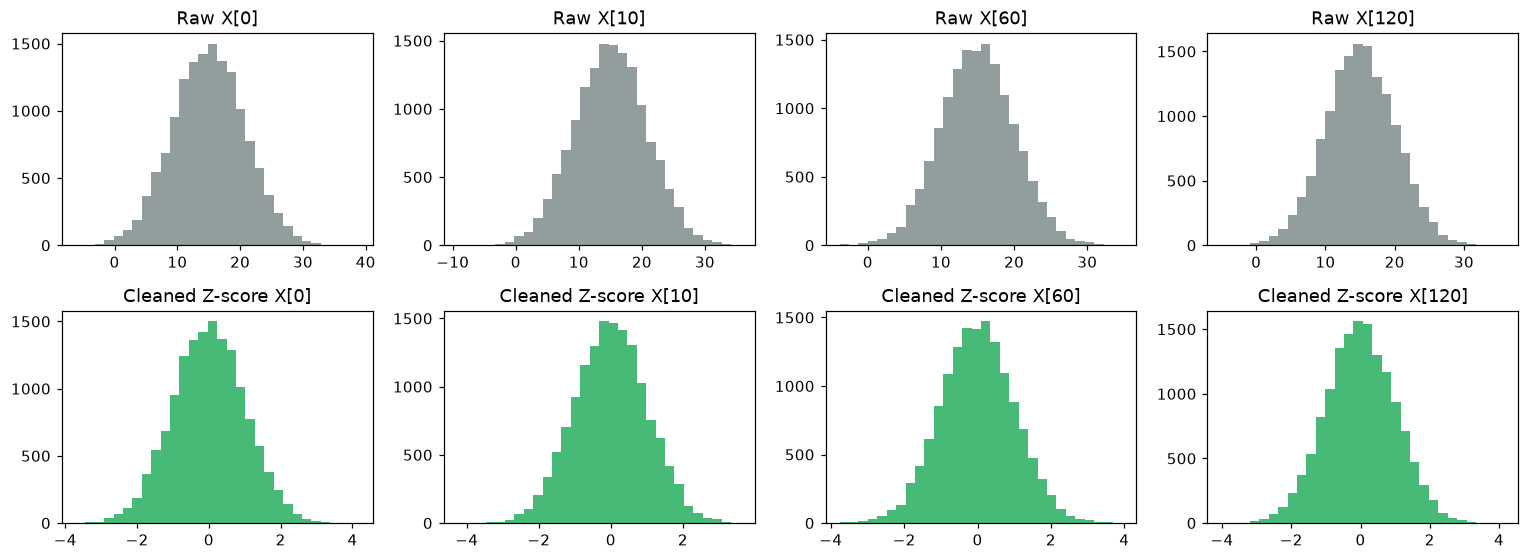

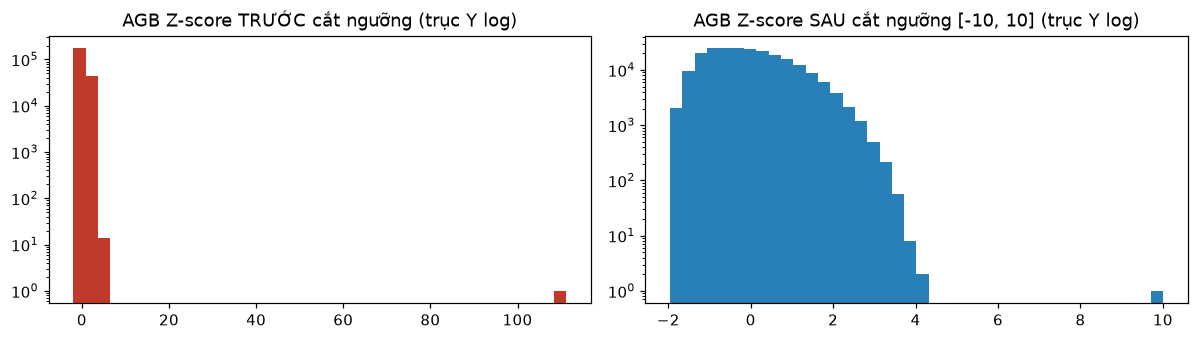

In [2]:
channels = [0, 10, 60, 120]
fig, axes = plt.subplots(2, 4, figsize=(14, 5.2))
for col_i, ch in enumerate(channels):
    raw_v = data["x_train"][..., ch].ravel()
    raw_v = raw_v[np.isfinite(raw_v)]
    axes[0, col_i].hist(raw_v, bins=30, color="#7f8c8d", alpha=0.85)
    axes[0, col_i].set_title(f"Raw X[{ch}]")

    axes[1, col_i].hist(x_clean[..., ch].ravel(), bins=30, color="#27ae60", alpha=0.85)
    axes[1, col_i].set_title(f"Cleaned Z-score X[{ch}]")
plt.tight_layout()
plt.show()

# Kiểm chứng cắt ngoại lai cực đoan trên biến agb
agb_idx = TREE_BAND.index("agb")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(y_norm[..., agb_idx].ravel(), bins=40, color="#c0392b", log=True)
axes[0].set_title("AGB Z-score TRƯỚC cắt ngưỡng (trục Y log)")
axes[1].hist(y_clean[..., agb_idx].ravel(), bins=40, color="#2980b9", log=True)
axes[1].set_title("AGB Z-score SAU cắt ngưỡng [-10, 10] (trục Y log)")
plt.tight_layout()
plt.show()

## 3. Động lực học chuỗi thời gian 40 năm theo điểm lưới (`site`)
Quan sát xu hướng biến động 40 năm (tháng 12, tuổi rừng khởi tạo `100`) của 4 biến sinh thái chính trên 6 điểm lưới khác nhau.

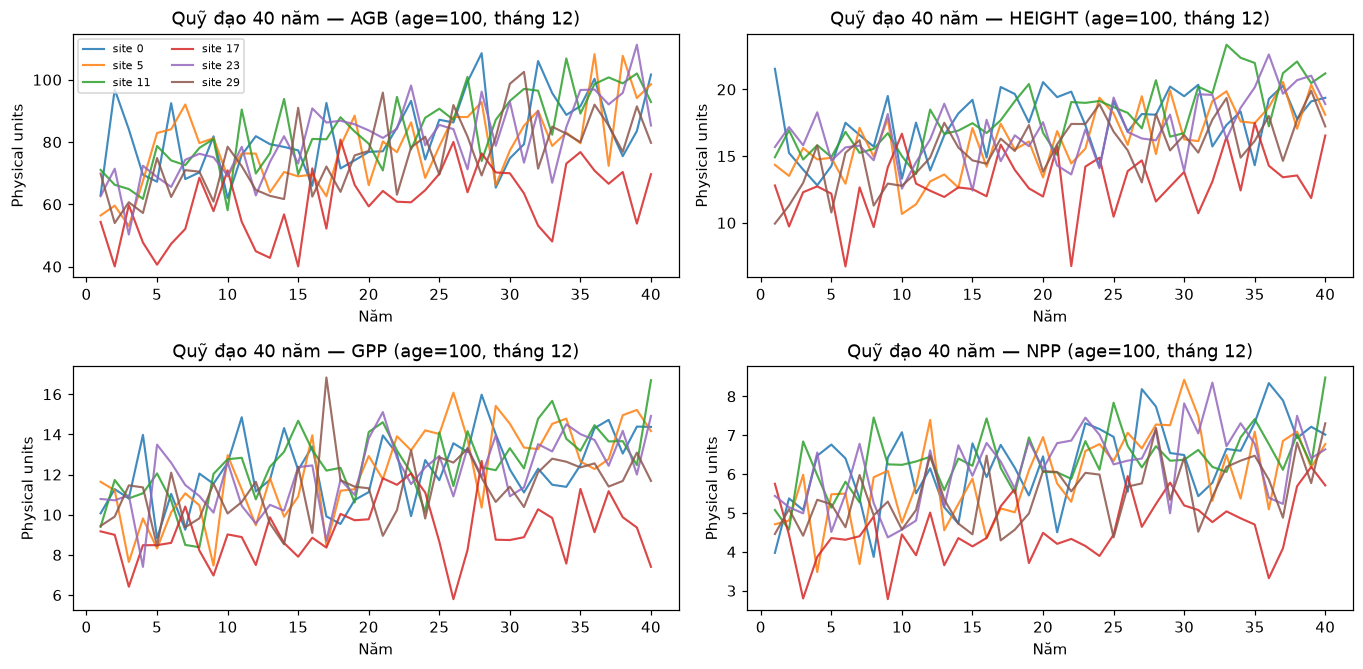

In [3]:
age_idx = AGES.index(100)
n_sites_avail = data["y_train"].shape[1]
sample_sites = np.linspace(0, n_sites_avail - 1, min(6, n_sites_avail), dtype=int)
years = np.arange(1, 41)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.2))
for ax, name in zip(axes.ravel(), ["agb", "height", "gpp", "npp"]):
    k = TREE_BAND.index(name)
    for s in sample_sites:
        series = data["y_train"][age_idx, s, 1:, 11, k]
        ax.plot(years, series, alpha=0.85, linewidth=1.4, label=f"site {s}")
    ax.set_title(f"Quỹ đạo 40 năm — {name.upper()} (age=100, tháng 12)")
    ax.set_xlabel("Năm"); ax.set_ylabel("Physical units")
axes[0, 0].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## 4. Ảnh hưởng của 15 mức tuổi rừng (`AGES`: 1 $\rightarrow$ 500 năm)
Khảo sát đường cong tăng trưởng trung bình của 7 biến mục tiêu theo tuổi rừng khởi tạo.

    height    agb   soil    lai    gpp    npp     rh
1   -1.377 -1.333 -1.379 -1.373 -1.389 -1.383 -1.386
10  -1.204 -1.160 -1.191 -1.200 -1.182 -1.206 -1.201
20  -1.016 -0.990 -1.026 -1.019 -1.023 -1.012 -1.009
30  -0.845 -0.817 -0.847 -0.837 -0.838 -0.832 -0.832
50  -0.656 -0.638 -0.658 -0.668 -0.652 -0.660 -0.651
70  -0.485 -0.470 -0.471 -0.476 -0.469 -0.483 -0.497


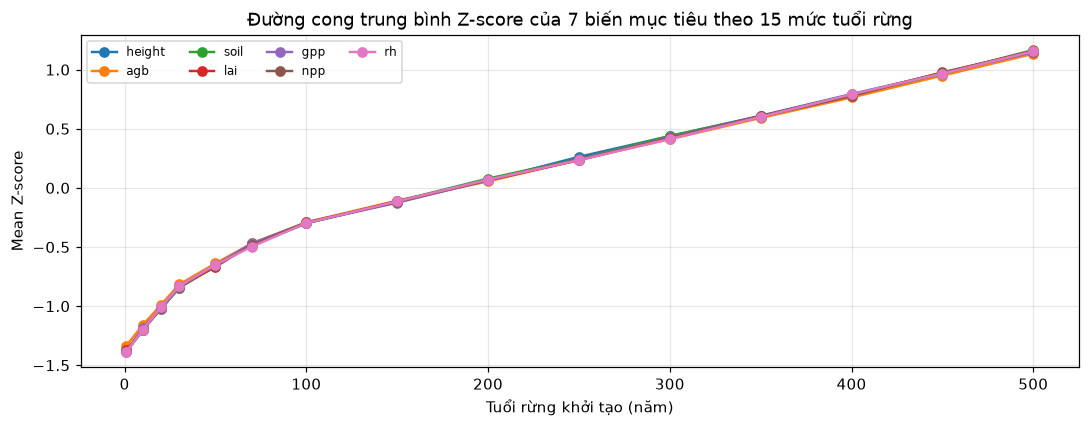

In [4]:
# Tính trung bình chuẩn hóa theo từng mức tuổi rừng (tháng 12, năm 1..40)
age_means = y_clean[:, :, 1:, 11, :].mean(axis=(1, 2))  # (15, 7)
age_df = pd.DataFrame(age_means, index=AGES, columns=TREE_BAND)
display(age_df.round(3).head(6))

fig, ax = plt.subplots(figsize=(10, 4.0))
for name in TREE_BAND:
    ax.plot(AGES, age_df[name], marker="o", linewidth=1.6, label=name)
ax.set_title("Đường cong trung bình Z-score của 7 biến mục tiêu theo 15 mức tuổi rừng")
ax.set_xlabel("Tuổi rừng khởi tạo (năm)"); ax.set_ylabel("Mean Z-score")
ax.legend(ncol=4, fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Phân tích Tương quan Chéo & Đa cộng tuyến (136 biến $X$ và 7 biến $Y$)

Tập đặc trưng One-Step-Ahead: X_feat=(18000, 144), Y_target=(18000, 7)
Số cặp kênh X có |r| > 0.85 (đa cộng tuyến mạnh): 0 / 9180


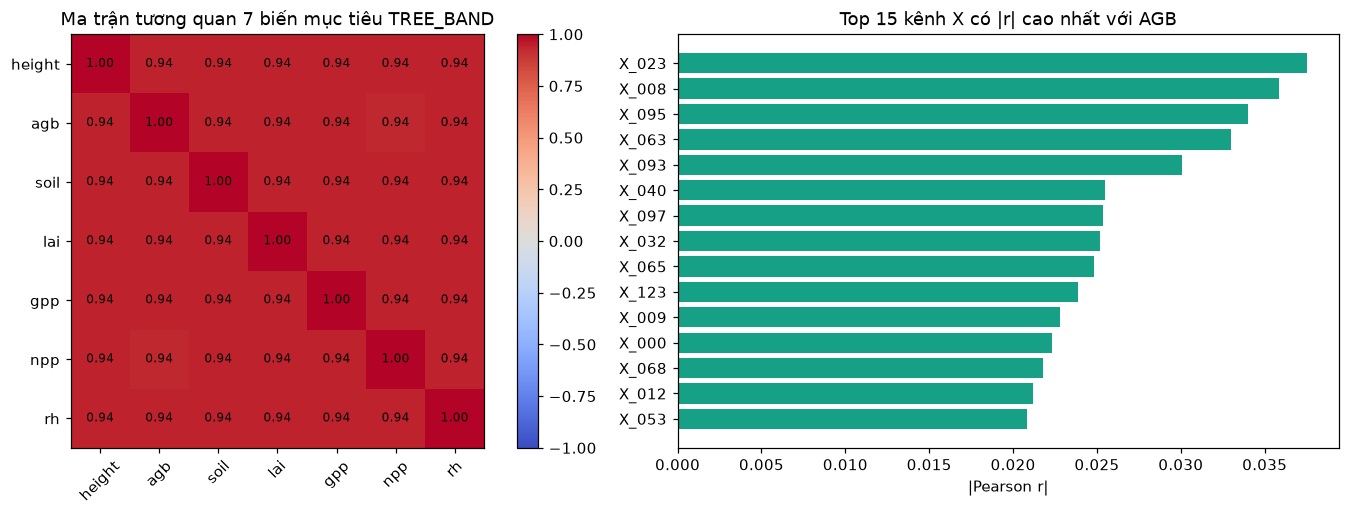

In [5]:
X_feat, Y_target = build_one_step_dataset(x_clean, y_clean, ages=AGES)
print(f"Tập đặc trưng One-Step-Ahead: X_feat={X_feat.shape}, Y_target={Y_target.shape}")

# 1. Ma trận tương quan 7 biến mục tiêu (có giá trị số trên từng ô)
y_df = pd.DataFrame(Y_target, columns=TREE_BAND)
corr_y = y_df.corr()

# 2. Top 15 kênh X tương quan tuyệt đối cao nhất với AGB
x_ann_df = pd.DataFrame(X_feat[:, :136], columns=[f"X_{i:03d}" for i in range(136)])
agb_corr = x_ann_df.apply(lambda col: col.corr(y_df["agb"])).abs().sort_values(ascending=False)

# 3. Kiểm tra đa cộng tuyến giữa 136 kênh X
corr_x = x_ann_df.corr().abs().values
tri_u = corr_x[np.triu_indices(136, k=1)]
print(f"Số cặp kênh X có |r| > 0.85 (đa cộng tuyến mạnh): {int((tri_u > 0.85).sum())} / {len(tri_u)}")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
im = axes[0].imshow(corr_y.values, cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(TREE_BAND))); axes[0].set_xticklabels(TREE_BAND, rotation=45)
axes[0].set_yticks(range(len(TREE_BAND))); axes[0].set_yticklabels(TREE_BAND)
for i in range(len(TREE_BAND)):
    for j in range(len(TREE_BAND)):
        axes[0].text(j, i, f"{corr_y.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
axes[0].set_title("Ma trận tương quan 7 biến mục tiêu TREE_BAND")
fig.colorbar(im, ax=axes[0], fraction=0.046)

top15 = agb_corr.head(15)[::-1]
axes[1].barh(top15.index, top15.values, color="#16a085")
axes[1].set_title("Top 15 kênh X có |r| cao nhất với AGB")
axes[1].set_xlabel("|Pearson r|")
plt.tight_layout()
plt.show()

## 6. Kiểm tra rò rỉ dữ liệu (Leakage Check) & Tương quan tự hồi quy bậc 1
Xác minh rằng vector trạng thái năm trước (`X_feat[:, 136:143]`) khớp chính xác với `Y_target` của bước $t-1$ và đo độ tự tương quan bậc 1 (`lag-1`) để lượng hóa rủi ro trôi sai số khi rollout 40 năm ở Tuần 3.

In [6]:
# Kiểm tra khớp lag-1 giữa prev_y trong X_feat và Y_target
prev_y_in_feat = X_feat[:, 136:143]
lag1_rows = []
for k, name in enumerate(TREE_BAND):
    r_lag1 = float(np.corrcoef(prev_y_in_feat[:, k], Y_target[:, k])[0, 1])
    mae_persist = float(np.mean(np.abs(Y_target[:, k] - prev_y_in_feat[:, k])))
    lag1_rows.append({
        "target": name,
        "lag1_autocorr": round(r_lag1, 4),
        "persistence_MAE_z": round(mae_persist, 4),
    })
lag1_df = pd.DataFrame(lag1_rows).set_index("target")
display(lag1_df)

# Kiểm tra không có rò rỉ tương lai: năm 1 của site 0 phải lấy y0, năm 2 lấy đúng y1
assert np.allclose(X_feat[1, 136:143], Y_target[0]), "Phát hiện sai lệch dịch chuyển thời gian!"
print("Leakage check PASSED: X_feat[t] sử dụng chính xác trạng thái tháng 12 năm t-1.")

out_path = ROOT / cfg["paths"]["processed_dir"] / "one_step_eda_ready.npz"
np.savez_compressed(out_path, X_feat=X_feat, Y_target=Y_target)
print("Đã lưu tập đặc trưng sẵn sàng cho Modeling Tuần 3 tại:", out_path)

        lag1_autocorr  persistence_MAE_z
target                                  
height         0.9435             0.2489
agb            0.9330             0.2482
soil           0.9421             0.2521
lai            0.9416             0.2533
gpp            0.9422             0.2500
npp            0.9410             0.2544
rh             0.9415             0.2523
Leakage check PASSED: X_feat[t] sử dụng chính xác trạng thái tháng 12 năm t-1.
Đã lưu tập đặc trưng sẵn sàng cho Modeling Tuần 3 tại: C:\Users\Phuong Linh\OneDrive\Desktop\project-khdl\data\processed\one_step_eda_ready.npz
